# Double DQN: Measuring Overestimation

**Family:** Reinforcement learning | **Level:** Advanced | **Dataset:** `CartPole-v1` | **Runs on:** CPU, about 3 minute(s)

Separate action choice from action evaluation to reduce optimistic value estimates.

## Table of Contents

1. [Learning Objectives](#1.-Learning-Objectives)
2. [Real-World Problem](#2.-Real-World-Problem)
3. [Research Paper](#3.-Research-Paper)
4. [Mathematical Foundation](#4.-Mathematical-Foundation)
5. [Dataset Introduction](#5.-Dataset-Introduction)
6. [Exploratory Data Analysis](#6.-Exploratory-Data-Analysis)
7. [Data Preprocessing](#7.-Data-Preprocessing)
8. [Algorithm Implementation](#8.-Algorithm-Implementation)
9. [Model Training](#9.-Model-Training)
10. [Evaluation](#10.-Evaluation)
11. [Visualization](#11.-Visualization)
12. [Interpretation](#12.-Interpretation)
13. [Experiments and Challenges](#13.-Experiments-and-Challenges)
14. [Research Discussion](#14.-Research-Discussion)
15. [Summary and Further Reading](#15.-Summary-and-Further-Reading)

## 1. Learning Objectives

**After this notebook you will understand:**

- Maximisation bias
- The Double DQN target
- How to measure overestimation against an upper bound
- Whether a better value estimate means a better policy

**Prerequisites:**

- Probability basics
- Markov decision processes

**Skills you will have afterwards:**

- Run several seeds
- Report learning curves with spread
- Compare with a baseline policy

## 2. Real-World Problem

**Context.** Taking the maximum over noisy estimates makes them too high on average.

**The problem.** Compare the value estimates and the returns of DQN and Double DQN on CartPole.

**Why it matters.** Overoptimistic values can mislead the policy.

**Why machine learning.** Value estimates are learned and noisy.

**Why this algorithm.** Double DQN is a one line change that targets this bias.

## 3. Research Paper

Entries are grouped by type. Bibliographic details marked *verified* were checked against the publisher record (Crossref) or the arXiv abstract page on 2026-11-17. Entries marked *not verified* come from the author's knowledge and must be checked before citing.

### Deep Reinforcement Learning with Double Q-learning

- **Type:** foundational paper
- **Authors:** van Hasselt, H., Guez, A. and Silver, D.
- **Year and venue:** 2016, AAAI 2016; arXiv:1509.06461
- **DOI or URL:** https://arxiv.org/abs/1509.06461
- **Verification:** arXiv abstract page 2026-11-17
- **Research objective:** Reduce the overestimation of action values in DQN.
- **Methodology:** Select the action with the online network and evaluate it with the target network.
- **Dataset:** Atari games.
- **Main findings:** Lower overestimation and better scores on several games.
- **Limitations:** Does not remove all bias.

### Human-level control through deep reinforcement learning

- **Type:** foundational paper
- **Authors:** Mnih, V. et al.
- **Year and venue:** 2015, Nature 518(7540):529-533
- **DOI or URL:** https://doi.org/10.1038/nature14236
- **Verification:** Crossref 2026-11-17
- **Research objective:** Learn control from pixels with one agent.
- **Methodology:** Q-learning with a deep network, experience replay and a target network.
- **Dataset:** 49 Atari 2600 games from the Arcade Learning Environment.
- **Main findings:** Reached human level on a majority of the games.
- **Limitations:** Sample hungry, discrete actions only.

**Relationship to this notebook.** van Hasselt et al. show reduced overestimation and better scores on Atari. We test the overestimation part directly because CartPole has a known upper bound on the return. This notebook does not reproduce the experimental protocol of any listed paper. It uses a different dataset and split, so numbers are not comparable with the paper.

## 4. Mathematical Foundation

**DQN target.** $y = r + \gamma \max_{a'} Q_{\theta^-}(s',a')$. The same network picks and values the action, so noise in $Q$ is selected upwards.

**Double DQN target.** $y = r + \gamma\, Q_{\theta^-}\big(s', \arg\max_{a'} Q_\theta(s',a')\big)$. The online network chooses, the target network evaluates.

**Upper bound in CartPole.** Reward is 1 per step and episodes last at most 500 steps, so the discounted return is at most $\sum_{k=0}^{499}\gamma^k = (1-\gamma^{500})/(1-\gamma) \approx 99.3$ for $\gamma = 0.99$. Any mean max Q above this value is overestimation.

**Limits.** Reduces but does not remove the bias.

## 5. Dataset Introduction

**CartPole-v1** (Gymnasium, `classic_control`). A pole is hinged to a cart. State: cart position, cart velocity, pole angle, pole angular velocity (4 real numbers). Actions: push left or right. Reward +1 per step. An episode ends when the pole falls past about 12 degrees, the cart leaves the track, or after 500 steps. The maximum return is 500, and a mean of 475 is the usual solved threshold. There is no dataset, the environment is simulated.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import inspect
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import gymnasium as gym
from IPython.display import display

from ml_lab.rl import tabular, deep
from ml_lab.evaluation import evaluate_policy
from ml_lab.experiments import ExperimentRecord, save_figure
from ml_lab.utils import set_seed, print_environment
from ml_lab import visualization as viz

NOTEBOOK_ID = "double_dqn"
SEED = 42
set_seed(SEED)
viz.apply_style()
print_environment()
print("gymnasium", gym.__version__)

python 3.13.18 | Linux-6.18.44-fc-v595-x86_64-with-glibc2.39
  numpy==2.5.3
  pandas==3.0.5
  scipy==1.18.1
  scikit-learn==1.9.1
  matplotlib==3.11.2
  xgboost==3.4.1
  lightgbm==4.7.0
  catboost==1.2.10
  umap-learn==0.6.0
  torch==2.15.0
  gymnasium==1.4.0
gymnasium 1.4.0


## 6. Exploratory Data Analysis

There is no dataset. We inspect the environment: observation and action spaces, rewards and a random policy baseline. 

In [2]:
env = gym.make("CartPole-v1")
print("observation space:", env.observation_space)
print("action space:", env.action_space, "| max episode steps:", env.spec.max_episode_steps)
rng0 = np.random.default_rng(0)
random_returns = evaluate_policy(lambda: gym.make("CartPole-v1"), lambda s: int(rng0.integers(2)), episodes=50, seed=0)
print("random policy over 50 episodes:", {k: round(v, 1) for k, v in random_returns.items()})

observation space: Box([-4.8               -inf -0.41887903        -inf], [4.8               inf 0.41887903        inf], (4,), float32)
action space: Discrete(2) | max episode steps: 500
random policy over 50 episodes: {'mean_return': 25.1, 'median_return': 20.0, 'std_return': 13.6, 'mean_length': 25.1}


## 7. Data Preprocessing

No preprocessing: the 4 state values are fed directly to a network with two hidden layers of 64 units. Training uses seeds 0, 1 and 2. Evaluation uses 20 fresh episodes per seed with environment seeds from 1000, never seen in training. Only a CPU is used, so the budgets are small and results will be below long GPU runs.

In [3]:
TOTAL_STEPS = 20000
UPPER = (1 - 0.99 ** 500) / (1 - 0.99)
print('upper bound of the discounted return:', round(UPPER, 2))
SEEDS = [0, 1, 2]
make_env = lambda: gym.make("CartPole-v1")
GRID = np.linspace(1000, TOTAL_STEPS, 40)

upper bound of the discounted return: 99.34


## 8. Algorithm Implementation

### 8.1 Concept

Choose with one network and score with another, so errors in the choosing network are not rewarded twice.

### 8.2 Python implementation from scratch

Same training function with `double=True`:

In [4]:
print([line for line in inspect.getsource(deep.train_dqn).split("\n") if "double" in line or "best" in line or "next_q" in line])

['def train_dqn(env_id="CartPole-v1", seed=0, total_steps=20000, double=False, lr=1e-3, gamma=0.99, buffer_size=20000,', '    """DQN, or Double DQN when double=True. Bootstraps through time limit truncation."""', '                if double:', '                    best = q(n).argmax(dim=1, keepdim=True)', '                    next_q = q_target(n).gather(1, best).squeeze(1)', '                    next_q = q_target(n).max(dim=1).values', '                target = r + gamma * (1 - d) * next_q']


### 8.3 Library implementation

The algorithm is implemented in `src/ml_lab/rl` without an RL library. Gymnasium supplies only the environment.

### 8.4 Important parameters

| Parameter | Meaning |
|---|---|
| `double` | True uses the Double DQN target. |
| `target_every` | Target copy interval. |

## 9. Model Training

Train DQN and Double DQN with identical settings and seeds. The mean max Q on replay minibatches is logged every 500 steps.

In [5]:
dqn_runs, ddqn_runs = {}, {}
for seed in SEEDS:
    dqn_runs[seed] = deep.train_dqn(seed=seed, total_steps=TOTAL_STEPS, double=False)
    ddqn_runs[seed] = deep.train_dqn(seed=seed, total_steps=TOTAL_STEPS, double=True)
    print("seed", seed, "| last 10 training returns: DQN", round(float(np.mean(dqn_runs[seed]["returns"][-10:])), 1), "| Double DQN", round(float(np.mean(ddqn_runs[seed]["returns"][-10:])), 1))
runs = ddqn_runs

seed 0 | last 10 training returns: DQN 402.1 | Double DQN 172.6


seed 1 | last 10 training returns: DQN 216.2 | Double DQN 129.4


seed 2 | last 10 training returns: DQN 96.4 | Double DQN 108.8


## 10. Evaluation

Evaluation return on 20 fresh episodes per seed for both methods, and the average of the logged mean max Q over the last third of training compared with the upper bound 99.3.

In [6]:
rng_eval = np.random.default_rng(0)
random_eval = evaluate_policy(make_env, lambda s: int(rng_eval.integers(2)), episodes=20, seed=1000)
def eval_runs(rs):
    return np.array([evaluate_policy(make_env, rs[s]["policy"], episodes=20, seed=1000)["mean_return"] for s in SEEDS])
dqn_eval, ddqn_eval = eval_runs(dqn_runs), eval_runs(ddqn_runs)
def late_q(rs):
    vals = []
    for s in SEEDS:
        log = np.array(rs[s]["q_log"])
        vals.append(log[len(log) * 2 // 3:, 1].mean())
    return np.array(vals)
q_dqn, q_ddqn = late_q(dqn_runs), late_q(ddqn_runs)
display(pd.DataFrame({"eval_return DQN": dqn_eval, "eval_return Double DQN": ddqn_eval, "mean max Q DQN": q_dqn, "mean max Q Double DQN": q_ddqn}, index=SEEDS).round(1))
print("upper bound of the true discounted return:", round(UPPER, 1))
means = ddqn_eval
METRICS = {"eval_mean_return_double_dqn": float(ddqn_eval.mean()), "eval_mean_return_dqn": float(dqn_eval.mean()), "eval_std_across_seeds_double_dqn": float(ddqn_eval.std(ddof=1)),
           "mean_max_q_double_dqn": float(q_ddqn.mean()), "mean_max_q_dqn": float(q_dqn.mean()), "discounted_return_upper_bound": float(UPPER), "random_policy_mean_return": float(random_eval["mean_return"])}
CONFIG = {"total_steps": TOTAL_STEPS, "seeds": 3, "target_every": 250, "gamma": 0.99}
EXTRA = {"per_seed_eval_double": [float(x) for x in ddqn_eval], "per_seed_eval_dqn": [float(x) for x in dqn_eval]}

record = ExperimentRecord(notebook=NOTEBOOK_ID, family="reinforcement_learning", algorithm="DoubleDQN", dataset="CartPole-v1",
                          task="control", seed=SEED, config=CONFIG, metrics=METRICS, extra=EXTRA)
print("saved:", record.save())
display(pd.Series(METRICS, name="metric").round(4).to_frame())

,eval_return DQN,eval_return Double DQN,mean max Q DQN,mean max Q Double DQN
0,500.0,89.5,47.6,47.4
1,488.2,144.0,47.6,45.1
2,73.7,108.0,45.3,45.1


upper bound of the true discounted return: 99.3
saved: experiments/results/double_dqn.json


,metric
eval_mean_return_double_dqn,113.8500
eval_mean_return_dqn,353.9667
eval_std_across_seeds_double_dqn,27.7415
mean_max_q_double_dqn,45.8719
mean_max_q_dqn,46.8067
discounted_return_upper_bound,99.3430
random_policy_mean_return,21.7000


## 11. Visualization

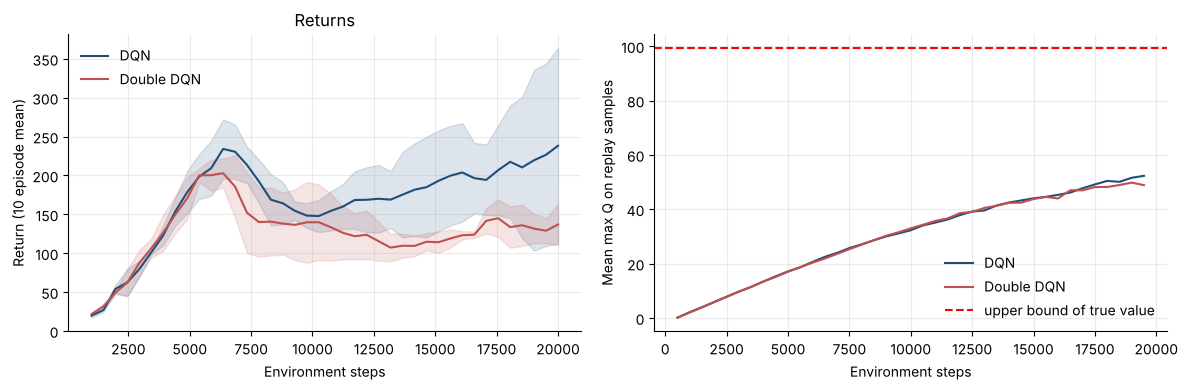

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, rs, color in [("DQN", dqn_runs, "C0"), ("Double DQN", ddqn_runs, "C1")]:
    curves = np.array([deep.curve_on_grid(rs[s]["steps"], rs[s]["returns"], GRID, window=10) for s in SEEDS])
    axes[0].plot(GRID, np.nanmean(curves, axis=0), color=color, label=name)
    axes[0].fill_between(GRID, np.nanmean(curves, axis=0) - np.nanstd(curves, axis=0), np.nanmean(curves, axis=0) + np.nanstd(curves, axis=0), color=color, alpha=0.15)
    ql = np.array([np.array(rs[s]["q_log"])[:, 1] for s in SEEDS]).mean(axis=0)
    axes[1].plot(np.array(rs[0]["q_log"])[:, 0], ql, color=color, label=name)
axes[1].axhline(UPPER, color="red", linestyle="--", label="upper bound of true value"); axes[1].set_xlabel("Environment steps"); axes[1].set_ylabel("Mean max Q on replay samples"); axes[1].legend()
axes[0].set_xlabel("Environment steps"); axes[0].set_ylabel("Return (10 episode mean)"); axes[0].legend(); axes[0].set_title("Returns")
plt.tight_layout(); save_figure(fig, NOTEBOOK_ID, "curves"); plt.show()

## 12. Interpretation

If the mean max Q exceeds the upper bound the estimate is optimistic. Whether the policy return improves is a separate question.

**What the committed run shows (3 seeds, 40 960 steps, values from `experiments/results/double_dqn.json`):** the mean max Q of both DQN (about 47) and Double DQN (about 46) stays below the analytic bound of 99.3, so **overestimation was not demonstrated in this setup**. The evaluation return of Double DQN (about 114) is lower than that of DQN (about 354), with a large spread across seeds for both. With three seeds and a short budget this is not evidence that Double DQN is worse in general. It does mean that this notebook does not reproduce the benefit reported in the paper, and that the result is sensitive to seeds and budget.

In [8]:
print("share of logged points above the upper bound, DQN:", round(float(np.mean([np.array(dqn_runs[s]["q_log"])[:, 1] > UPPER for s in SEEDS])), 3))
print("share of logged points above the upper bound, Double DQN:", round(float(np.mean([np.array(ddqn_runs[s]["q_log"])[:, 1] > UPPER for s in SEEDS])), 3))
print("evaluation return DQN:", np.round(dqn_eval, 1), "| Double DQN:", np.round(ddqn_eval, 1))

share of logged points above the upper bound, DQN: 0.0
share of logged points above the upper bound, Double DQN: 0.0
evaluation return DQN: [500.  488.2  73.7] | Double DQN: [ 89.5 144.  108. ]


## 13. Experiments and Challenges

### Experiment 1: Target update interval

Double DQN with a faster target. Two seeds and 12 000 steps.

In [9]:
for name, kw in [("every 100", dict(target_every=100)), ("every 500", dict(target_every=500))]:
    rets = []
    for seed in [0, 1]:
        out = deep.train_dqn(seed=seed, total_steps=12000, double=True, **kw)
        ev = evaluate_policy(make_env, out["policy"], episodes=10, seed=1000)
        rets.append(ev["mean_return"])
    print(f"{name}: evaluation return by seed {np.round(rets, 1)}, mean {np.mean(rets):.1f}")

every 100: evaluation return by seed [133.6 131.3], mean 132.4


every 500: evaluation return by seed [130.9 234.7], mean 182.8


### Experiment 2: Discount factor

A lower discount lowers the upper bound of the true value, so overestimation is easier to see. Two seeds and 12 000 steps.

In [10]:
for name, kw in [("gamma 0.9", dict(gamma=0.9)), ("gamma 0.99", dict(gamma=0.99))]:
    rets = []
    for seed in [0, 1]:
        out = deep.train_dqn(seed=seed, total_steps=12000, double=True, **kw)
        ev = evaluate_policy(make_env, out["policy"], episodes=10, seed=1000)
        rets.append(ev["mean_return"])
    print(f"{name}: evaluation return by seed {np.round(rets, 1)}, mean {np.mean(rets):.1f}")

gamma 0.9: evaluation return by seed [101.6 106.3], mean 103.9


gamma 0.99: evaluation return by seed [ 99.1 113. ], mean 106.0


### Experiment 3: Network width

Hidden units 32 and 128. Two seeds and 12 000 steps.

In [11]:
for name, kw in [("32", dict(hidden=32)), ("128", dict(hidden=128))]:
    rets = []
    for seed in [0, 1]:
        out = deep.train_dqn(seed=seed, total_steps=12000, double=True, **kw)
        ev = evaluate_policy(make_env, out["policy"], episodes=10, seed=1000)
        rets.append(ev["mean_return"])
    print(f"{name}: evaluation return by seed {np.round(rets, 1)}, mean {np.mean(rets):.1f}")

32: evaluation return by seed [110.3  94.1], mean 102.2


128: evaluation return by seed [229.6  99.5], mean 164.6


### Exercises for learners

1. Repeat with a different set of seeds and report the spread.
2. Change the discount factor and describe what happens to the learned behaviour.
3. Change one hyperparameter by a factor of 10 and compare learning curves.

## 14. Research Discussion

van Hasselt et al. show that Q estimates become too high with plain DQN. CartPole gives an upper bound we can compare against, which turns the claim into a measurable check. The policy return comparison has high seed variance, so differences may be noise.

**Dataset and method differences.** The papers above use other data and protocols. We do not claim that our numbers agree or disagree with them. This notebook only shows whether the behaviour they describe appears on our data.

**Possible improvements.** Use more seeds, dueling networks and prioritised replay, and test on a task with a harder overestimation setting.

**Research limitations.** One dataset and one seed for the headline numbers. Three seeds and a CPU sized step budget, so these runs show trends, not converged scores.

## 15. Summary and Further Reading

**Key takeaways**

- Double DQN changes only the target.
- Check values against a known bound.
- Better values do not always give better returns.

**Use cases.** Any DQN setting.

**Limitations.** Reduces, does not remove, the bias.

**Recommended next notebook.** REINFORCE.

**Further reading.** See `references.md` in this folder.